## Adaline

#### add libs

In [75]:
!uv add numpy
!uv add pandas
!uv add matplotlib

Resolved 20 packages in 3ms
Audited 19 packages in 0.31ms
Resolved 20 packages in 3ms
Audited 19 packages in 0.30ms
Resolved 20 packages in 3ms
Audited 19 packages in 0.29ms


#### add required libs

In [76]:
import numpy as np
import matplotlib.pyplot as plt

#### Generate random data 

In [77]:
n_samples=50
np.random.seed(42)
x1_cats = np.random.uniform(0, 5, n_samples)
x2_cats = np.random.uniform(0, 5, n_samples)
y_cats = np.ones(n_samples) * -1  # Class label -1 for cats


x1_dogs=np.random.uniform(4,8,n_samples)
x2_dogs=np.random.uniform(4,8,n_samples)
y_dogs=np.ones(n_samples)  # Class label 1 for dogs


cats_stack=np.stack([np.ones(n_samples),x1_cats,x2_cats,y_cats],axis=1)
dogs_stack=np.stack([np.ones(n_samples),x1_dogs,x2_dogs,y_dogs],axis=1)
data=np.concatenate([cats_stack,dogs_stack],axis=0) # x1,x2,y

shuffled_data=data[np.random.permutation(n_samples*2)]


x=shuffled_data[:,:-1]
y=shuffled_data[:,-1]

In [78]:
w=np.random.randn(3)
w0,w1,w2=w
print(f"Initional Wights w0={w0} , w1={w1} , w2={w2}")
epchos=100000
eta=.02
errors=[]

Initional Wights w0=0.5150476863060478 , w1=3.8527314906547208 , w2=0.570890510693167


#### Learning

In [79]:
for i in range(epchos):
    z=x@w   # samples*features  . wights*1=features.      samples*1
    error=z-y
    
    w = w - eta * (x.T @ error) / len(x)
    
    errors.append(np.mean(error**2)*.5)
    
    if errors[i]<1e-6:
        break            
        

In [80]:
w0,w1,w2=w
print(f"Final Wights w0={w0} , w1={w1} , w2={w2} at epcho ={i}")


Final Wights w0=-1.8235188849466122 , w1=0.22698301917884678 , w2=0.21058668571992084 at epcho =99999


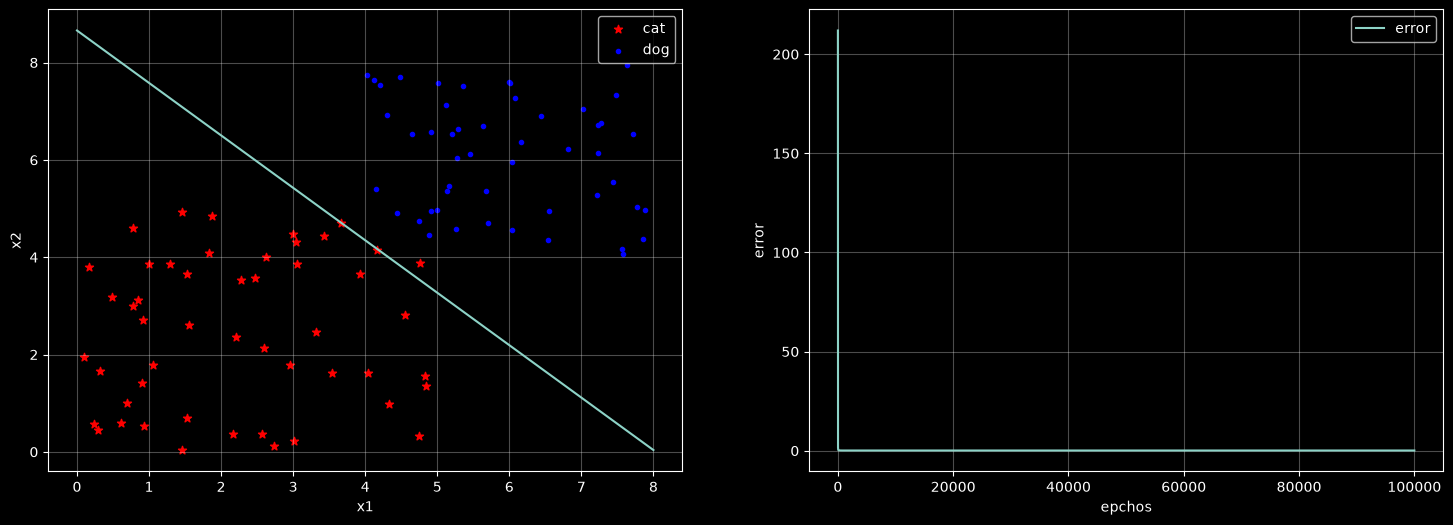

In [81]:
plt.style.use("dark_background")
plt.figure(figsize=(18,6))
plt.subplot(1,2,1)
plt.grid(alpha=.3)
plt.scatter(x1_cats,x2_cats,marker="*",color="red",label="cat")
plt.scatter(x1_dogs,x2_dogs,marker=".",color="blue",label="dog")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()


# z=w0*x0 + w1*x1 + w2*x2 
# w0*x0 + w1*x1 + w2*x2 = 0
# w2*x2 = -(w0*x0 + w1*x1)
# x2 = -(w0*x0 + w1*x1) / w2
# x2 = -(w0 + w1*x1) / w2


lx=np.linspace(0,8,100)
ly=-(w0 + w1*lx) / w2

plt.plot(lx,ly,label="line")

plt.subplot(1,2,2)
plt.grid(alpha=.3)
plt.plot(errors,label="error")
plt.xlabel("epchos")
plt.ylabel("error")
plt.legend()
plt.show()

In [82]:
predicions= (x[:,0]*w0) + (x[:,1]*w1) + (x[:,2]*w2)
predicions=np.where(predicions>=0,1,-1)
accuracy=np.mean(predicions==y)
print(f'Accuracy: {accuracy * 100:0.2f}%')

Accuracy: 99.00%
